<center><h1>Du_Isabelle_HW5</h1></center>
<br>
<br>

Name: Isabelle Du
<br>
Github Username: yxd-1213
<br>
USC ID: 5984907579

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import LabelEncoder

### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
cols = ["Temperature","Nausea","Lumbar_Pain","Urine_Pushing",
        "Micturition_Pain","Burning_Urethra",
        "Bladder_Inflammation","Nephritis"]

acute_df = pd.read_csv(
    "acute+inflammations/diagnosis.data",
    sep="\t", header=None, names=cols,
    encoding="utf-16", decimal=","
)

print("Shape:", acute_df.shape)

Shape: (120, 8)


### (b) Build a decision tree

In [3]:
X = acute_df.iloc[:, :6].copy()
binary_cols = X.columns[1:]
X[binary_cols] = X[binary_cols].replace({"yes":1, "no":0}).astype(int)

y = acute_df.iloc[:, 6].str.cat(acute_df.iloc[:, 7], sep="_")

tree_model = DecisionTreeClassifier(random_state=1).fit(X, y)

print(f"Depth: {tree_model.get_depth()}, "
      f"Leaves: {tree_model.get_n_leaves()}, "
      f"Accuracy: {tree_model.score(X, y):.3f}")

Depth: 4, Leaves: 6, Accuracy: 1.000


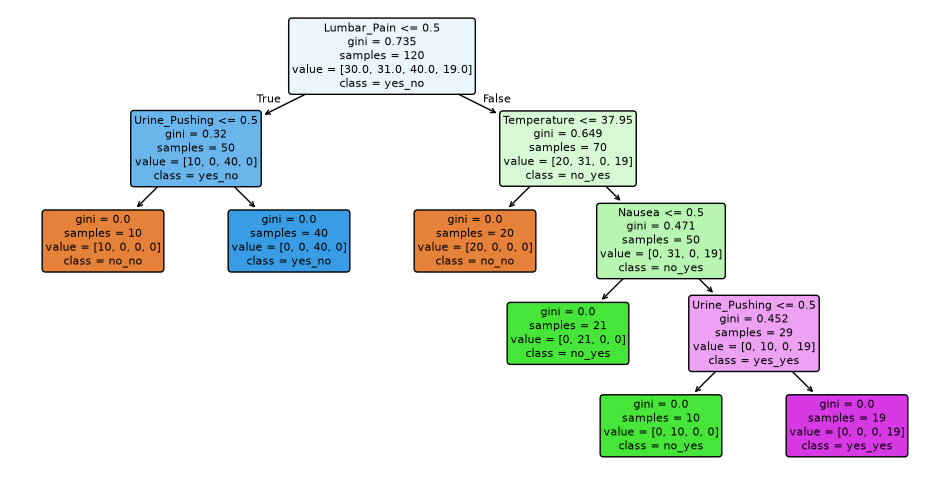

In [4]:
# Plot the decision tree

plt.figure(figsize=(12, 6))
plot_tree(tree_model, feature_names=X.columns,
          class_names=tree_model.classes_,
          filled=True, rounded=True, fontsize=8)
plt.show()

### (c) Convert the decision rules

Rule 1: IF Lumbar_Pain = no AND Urine_Pushing = no, THEN class = no_no.

Rule 2: IF Lumbar_Pain = no AND Urine_Pushing = yes, THEN class = yes_no.

Rule 3: IF Lumbar_Pain = yes AND Temperature <= 37.95, THEN class = no_no.

Rule 4: IF Lumbar_Pain = yes AND Temperature > 37.95 AND Nausea = no, THEN class = no_yes.

Rule 5: IF Lumbar_Pain = yes AND Temperature > 37.95 AND Nausea = yes AND Urine_Pushing = no, THEN class = no_yes.

Rule 6: IF Lumbar_Pain = yes AND Temperature > 37.95 AND Nausea = yes AND Urine_Pushing = yes, THEN class = yes_yes.

### 1.4. (d) Cost-Complexity Pruning

In [5]:
path = tree_model.cost_complexity_pruning_path(X, y)
alphas = path.ccp_alphas[:-1]

scores = [
    cross_val_score(
        DecisionTreeClassifier(random_state=1, ccp_alpha=a),
        X, y, cv=5
    ).mean()
    for a in alphas
]

i = np.argmax(scores)

print(f"Best alpha: {alphas[i]:.4f}, "
      f"CV accuracy: {scores[i]:.3f}")

Best alpha: 0.0000, CV accuracy: 0.958


The best CV accuracy was obtained at ccp_alpha = 0, so pruning did not improve the model. The original tree is already small with 6 leaves and is easy to interpret. Therefore, the six IF-THEN rules from part (c) remain the final decision rules.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [6]:
# Load data and split into training/test sets

path = "communities+and+crime"

with open(f"{path}/communities.names", errors="ignore") as f:
    cols = [line.split()[1] for line in f if line.startswith("@attribute")]

crime_df = pd.read_csv(
    f"{path}/communities.data",
    header=None,
    names=cols,
    na_values="?"
)

train_df = crime_df.iloc[:1495].copy()
test_df = crime_df.iloc[1495:].copy()

print("Full:", crime_df.shape,
      "Train:", train_df.shape,
      "Test:", test_df.shape)

Full: (1994, 128) Train: (1495, 128) Test: (499, 128)


### (b) Missing values

In [7]:
from sklearn.impute import SimpleImputer

drop_cols = ["state", "county", "community", "communityname", "fold"]
target = "ViolentCrimesPerPop"

X_train = train_df.drop(columns=drop_cols + [target])
y_train = train_df[target]
X_test = test_df.drop(columns=drop_cols + [target])
y_test = test_df[target]

print("Missing before:", X_train.isna().sum().sum() + X_test.isna().sum().sum())

imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train),
                       columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test),
                      columns=X_test.columns, index=X_test.index)

print("Missing after:", X_train.isna().sum().sum() + X_test.isna().sum().sum())
print("Number of predictors:", X_train.shape[1])

Missing before: 36851
Missing after: 0
Number of predictors: 122


### (c) Plot a correlation matrix

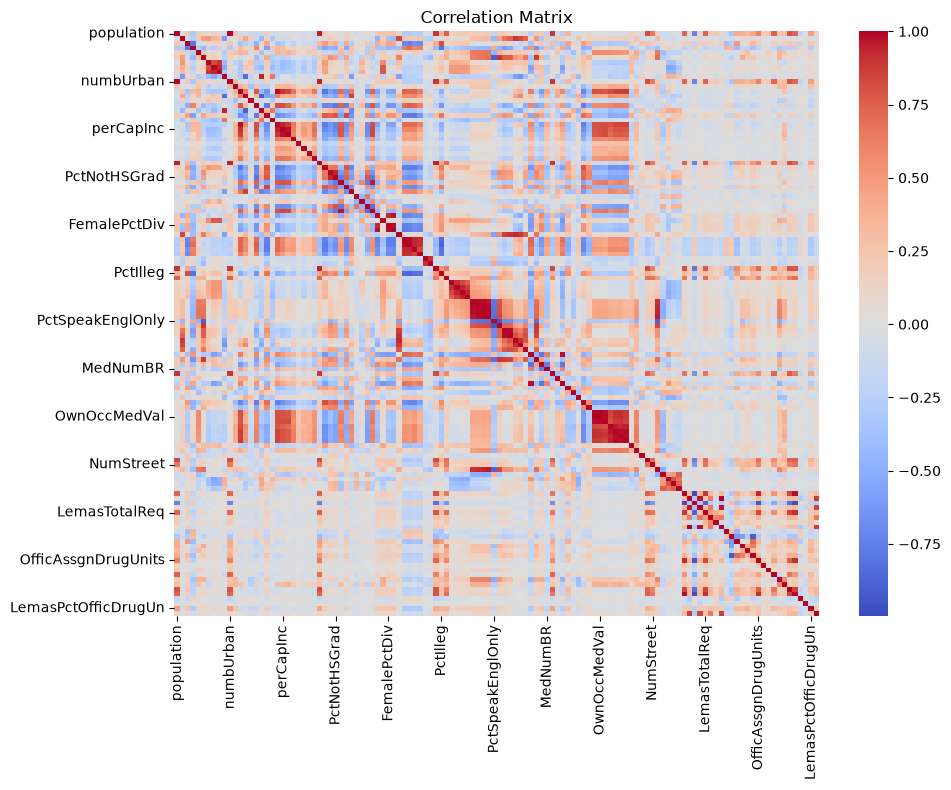

In [8]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    X_train.corr(),
    cmap="coolwarm",
    center=0,
    xticklabels=10,
    yticklabels=10
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [9]:
cv = X_train.std(ddof=1) / X_train.mean().replace(0, np.nan)
top11 = cv.sort_values(ascending=False).head(11)

top11

PctPolicAsian          5.527059
NumStreet              4.292923
NumInShelters          3.470952
NumIlleg               3.058964
NumImmig               2.926635
LemasPctOfficDrugUn    2.552946
NumUnderPov            2.342443
LemasSwornFT           2.248042
population             2.241105
numbUrban              2.038461
HousVacant             1.968467
dtype: float64

### (e) Scatter plots and box plots for highest CV features

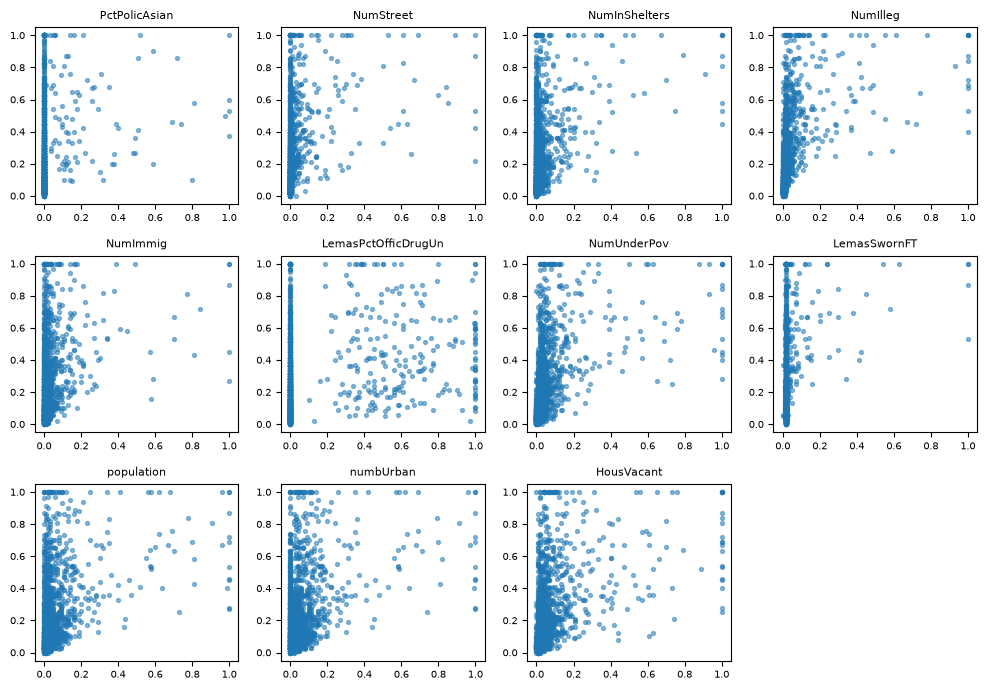

In [10]:
# Scatter plots for the 11 features with highest CV

features = top11.index

fig, axes = plt.subplots(3, 4, figsize=(10, 7))
axes = axes.ravel()

for ax, col in zip(axes, features):
    ax.scatter(X_train[col], y_train, s=8, alpha=0.5)
    ax.set_title(col, fontsize=8)
    ax.tick_params(labelsize=7)

axes[-1].axis("off")
plt.tight_layout()
plt.show()

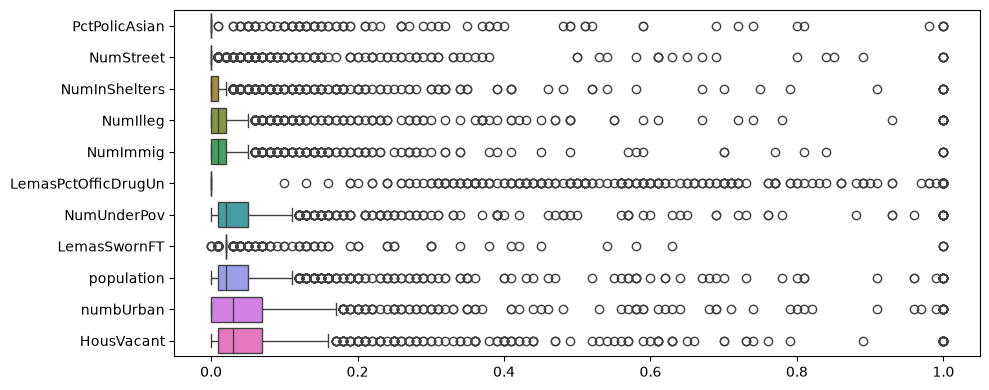

In [11]:
# Box plots for the 11 features

plt.figure(figsize=(10, 4))
sns.boxplot(data=X_train[features], orient="h")
plt.tight_layout()
plt.show()

The scatter plots can show possible relationships and outliers, but they are not enough to determine whether a feature is statistically significant. A regression model or statistical test would be needed to make that conclusion.

### (f) Fit a linear model

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

lm = LinearRegression().fit(X_train, y_train)
pred = lm.predict(X_test)

print("Test MSE:", round(mean_squared_error(y_test, pred), 4))

Test MSE: 0.018


### (g) Fit a ridge regression model

In [13]:
from sklearn.linear_model import RidgeCV

ridge = RidgeCV(
    alphas=np.logspace(-4, 4, 100),
    cv=5,
    scoring="neg_mean_squared_error"
).fit(X_train, y_train)

ridge_pred = ridge.predict(X_test)

print("Best lambda:", round(ridge.alpha_, 4))
print("Test MSE:", round(mean_squared_error(y_test, ridge_pred), 4))

Best lambda: 2.3101
Test MSE: 0.0175


### (h) Fit a LASSO model

In [14]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

# Raw LASSO
lasso = LassoCV(cv=5, max_iter=100000).fit(X_train, y_train)
lasso_mse = mean_squared_error(y_test, lasso.predict(X_test))
raw = set(X_train.columns[np.abs(lasso.coef_) > 1e-8])

# Standardized LASSO
scaler = StandardScaler()
Xtr_s = scaler.fit_transform(X_train)
Xte_s = scaler.transform(X_test)

lasso_s = LassoCV(cv=5, max_iter=100000).fit(Xtr_s, y_train)
lasso_s_mse = mean_squared_error(y_test, lasso_s.predict(Xte_s))
std = set(X_train.columns[np.abs(lasso_s.coef_) > 1e-8])

common = sorted(raw & std)
raw_only = sorted(raw - std)
std_only = sorted(std - raw)

print(f"Raw: alpha={lasso.alpha_:.5f}, MSE={lasso_mse:.4f}, selected={len(raw)}")
print(f"Standardized: alpha={lasso_s.alpha_:.5f}, MSE={lasso_s_mse:.4f}, selected={len(std)}")

print("\nSelected by both:")
print(", ".join(common))

print("\nRaw only:")
print(", ".join(raw_only) if raw_only else "None")

print("\nStandardized only:")
print(", ".join(std_only) if std_only else "None")

Raw: alpha=0.00012, MSE=0.0176, selected=74
Standardized: alpha=0.00076, MSE=0.0177, selected=72

Selected by both:
AsianPerCap, FemalePctDiv, HispPerCap, HousVacant, LandArea, LemasGangUnitDeploy, LemasPctPolicOnPatr, LemasSwFTFieldPerPop, MalePctDivorce, MalePctNevMarr, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, MedRent, MedRentPctHousInc, MedYrHousBuilt, NumIlleg, NumImmig, NumInShelters, NumKindsDrugsSeiz, NumStreet, OtherPerCap, PctEmplManu, PctEmploy, PctForeignBorn, PctHousLess3BR, PctHousNoPhone, PctHousOccup, PctIlleg, PctImmigRec10, PctKids2Par, PctLargHouseOccup, PctLess9thGrade, PctNotSpeakEnglWell, PctPersDenseHous, PctPersOwnOccup, PctPolicAsian, PctPolicBlack, PctPolicHisp, PctPopUnderPov, PctRecImmig10, PctSameCity85, PctTeen2Par, PctUsePubTrans, PctVacMore6Mos, PctVacantBoarded, PctWOFullPlumb, PctWorkMom, PctYoungKids2Par, PersPerOccupHous, PolicAveOTWorked, PolicCars, PolicReqPerOffic, PopDens, RacialMatchCommPol, RentLowQ, agePct12t21, agePct12t29, blackPerCap, indian

The raw and standardized LASSO models have very similar test errors. This is expected because the predictors in this data set are already normalized.

### (i) Fit a PCR model

In [15]:
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

pcr = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA()),
    ("lm", LinearRegression())
])

grid = GridSearchCV(
    pcr,
    {"pca__n_components": range(1, X_train.shape[1] + 1)},
    cv=5,
    scoring="neg_mean_squared_error"
).fit(X_train, y_train)

pcr_pred = grid.predict(X_test)

print("Best M:", grid.best_params_["pca__n_components"])
print("Test MSE:", round(mean_squared_error(y_test, pcr_pred), 4))

Best M: 95
Test MSE: 0.0183


### (j) Fit a boosting tree

In [17]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=1
)

grid = GridSearchCV(
    xgb,
    {"reg_alpha": [0, 1e-4, 1e-3, 1e-2, 0.1, 1, 10]},
    cv=5,
    scoring="neg_mean_squared_error"
).fit(X_train, y_train)

xgb_pred = grid.predict(X_test)

print("Best alpha:", grid.best_params_["reg_alpha"])
print("Test MSE:", round(mean_squared_error(y_test, xgb_pred), 4))

Best alpha: 1
Test MSE: 0.0179
